# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнила студентка гр. 3383 Кривошеина Дарья Александровна. Вариант №14.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Линейная дискретная система с нулевыми начальными условиями описывается импульсной характеристикой $h(n)$ и разностным уравнением. Для входа $x(n)$ и выхода $y(n)$ справедлива свёртка:

$$
y(n)=\sum_{m=-\infty}^{\infty}x(m)h(n-m).
$$

Для рекурсивного звена второго порядка с коэффициентами $b_0,b_1,b_2,a_0,a_1,a_2$ разностное уравнение имеет вид:

$$
a_0y(n)+a_1y(n-1)+a_2y(n-2)=b_0x(n)+b_1x(n-1)+b_2x(n-2).
$$

Передаточная функция является отношением $H(z)=B(z)/A(z)$. Её нули — корни числителя, полюсы — корни знаменателя. Для причинного рационального фильтра устойчивость обеспечивается расположением всех полюсов строго внутри единичной окружности. Частотная характеристика получается подстановкой $z=e^{j\hat{\omega}}$, её модуль и аргумент задают АЧХ и ФЧХ.

Для последовательности длины $N$ прямое и обратное дискретные преобразования Фурье определяются формулами:

$$
X(k)=\sum_{n=0}^{N-1}x(n)e^{-j2\pi kn/N},\qquad
x(n)=\frac{1}{N}\sum_{k=0}^{N-1}X(k)e^{j2\pi kn/N}.
$$

Нормированная угловая частота равна $\hat{\omega}=2\pi k/N$, а частота в герцах — $f=kf_{д}/N$. Равенство Парсеваля связывает энергию последовательности и её ДПФ:

$$
\sum_{n=0}^{N-1}|x(n)|^2=\frac{1}{N}\sum_{k=0}^{N-1}|X(k)|^2.
$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1

#### Пункт 1. Импульсная характеристика

В первом пункте рассчитывается импульсная характеристика звена второго порядка. По заданным коэффициентам передаточной функции последовательно вычисляются первые $N_1=24$ отсчёта отклика на единичный импульс $u_0(n)$ при нулевых начальных условиях. Ниже приведены код расчёта и график полученной последовательности.

 n       h(n)
 0   0.7800000000
 1  -1.8401760000
 2   2.7586304928
 3  -1.7788960458
 4   0.0089904836
 5   1.2777812697
 6  -1.4475908261
 7   0.7074792944
 8   0.2501606098
 9  -0.7943461450
10   0.7147473008
11  -0.2309853968
12  -0.2569717152
13   0.4570461277
14  -0.3294091010
15   0.0406061877
16   0.1926965307
17  -0.2467220272
18   0.1387408140
19   0.0221548576
20  -0.1254345978
21   0.1254250225
22  -0.0506396915
23  -0.0336962721


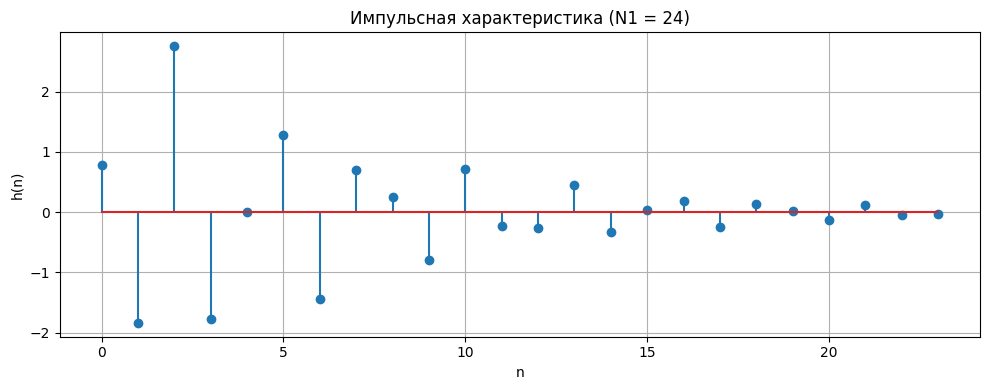

In [24]:
b = [0.78, -0.960492, 1.248]
a = [1.0, 1.1278, 0.724]
N1 = 24

h = []
for n in range(N1):
    input_part = b[n] if n < len(b) else 0.0
    feedback = 0.0
    for k in (1, 2):
        previous_index = n - k
        if previous_index >= 0:
            feedback += a[k] * h[previous_index]
    h.append((input_part - feedback) / a[0])

print(" n       h(n)")
for n, value in enumerate(h):
    print(f"{n:2d}  {value: .10f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.stem(range(N1), h)
plt.xlabel("n")
plt.ylabel("h(n)")
plt.title("Импульсная характеристика (N1 = 24)")
plt.grid(True)
plt.tight_layout()
plt.show()

##### Аналитическое выражение и результат

Передаточная функция:

$$
H(z) = \frac{0.78 - 0.960492z^{-1} + 1.248z^{-2}}{1 + 1.1278z^{-1} + 0.724z^{-2}}.
$$

При нулевых начальных условиях разностное уравнение имеет вид

$$
y(n) = 0.78x(n) - 0.960492x(n-1) + 1.248x(n-2)
- 1.1278y(n-1) - 0.724y(n-2),
$$

где значения $x(n)$ и $y(n)$ при $n < 0$ принимаются равными нулю. Для импульсного входа $x(n) = u_0(n)$, где $u_0(n)=1$ при $n=0$ и $u_0(n)=0$ при $n \ne 0$, получаем:

$$
h(0) = 0.78, \qquad h(1) = -1.840176, \qquad h(2) = 2.7586304928,
$$

$$
h(n) = -1.1278h(n-1) - 0.724h(n-2), \qquad n \ge 3.
$$

Для $n \ge 1$ ту же характеристику можно записать явно:

$$
h(n) = r^{n-1}\left(h(1)\cos((n-1)\theta) + 2.700832\sin((n-1)\theta)\right),
$$

где $r = \sqrt{0.724} \approx 0.850882$ и $\theta \approx 2.295247$ рад. Так как $r < 1$, отсчёты затухают. Однако полюса не сокращаются нулями, поэтому импульсная характеристика в точности не становится нулевой и её математическая длина бесконечна. В таблице и на графике показаны первые $N_1=24$ отсчёта.

#### Пункт 2. Реакция системы методом свёртки

Задаётся прямоугольное воздействие длины $N_2=34$: первые 17 отсчётов равны единице, остальные — нулю. Затем вычисляется линейная свёртка воздействия с рассчитанными в пункте 1 первыми $N_1=24$ отсчётами импульсной характеристики. Полная свёртка содержит 57 отсчётов, дополнительно строится реакция, ограниченная длиной воздействия.

Длина воздействия x(n): 34 отсчёта
Длительность прямоугольного импульса: 17 ненулевых отсчётов
Полная длина свёртки: 57 отсчётов
Длина y1(n) после ограничения до длины воздействия: 34 отсчётов


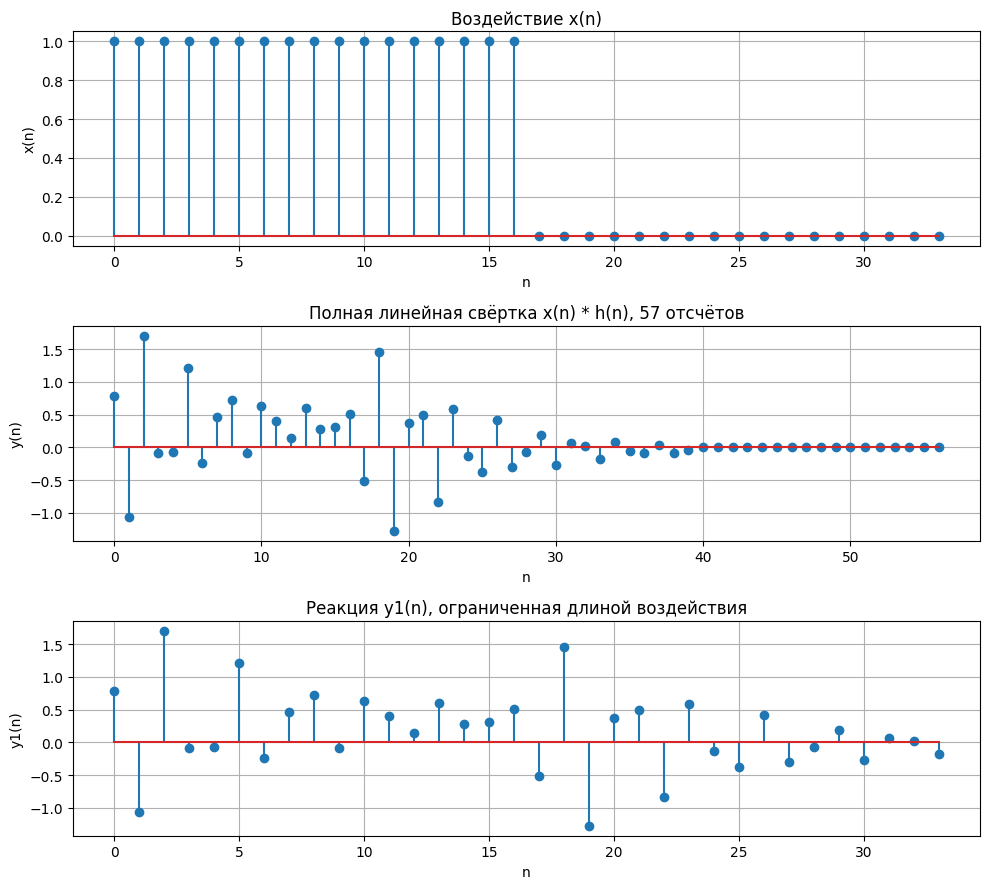

In [25]:
import numpy as np
import matplotlib.pyplot as plt

N2 = 34
pulse_length = int(N2 / 2 + 0.5) 
x = np.zeros(N2)
x[:pulse_length] = 1.0

y_full = np.convolve(x, h)
y1 = y_full[:N2]

print(f"Длина воздействия x(n): {len(x)} отсчёта")
print(f"Длительность прямоугольного импульса: {pulse_length} ненулевых отсчётов")
print(f"Полная длина свёртки: {len(y_full)} отсчётов")
print(f"Длина y1(n) после ограничения до длины воздействия: {len(y1)} отсчётов")

fig, axes = plt.subplots(3, 1, figsize=(10, 9))
axes[0].stem(range(N2), x)
axes[0].set_title("Воздействие x(n)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("x(n)")
axes[0].grid(True)

axes[1].stem(range(len(y_full)), y_full)
axes[1].set_title("Полная линейная свёртка x(n) * h(n), 57 отсчётов")
axes[1].set_xlabel("n")
axes[1].set_ylabel("y(n)")
axes[1].grid(True)

axes[2].stem(range(N2), y1)
axes[2].set_title("Реакция y1(n), ограниченная длиной воздействия")
axes[2].set_xlabel("n")
axes[2].set_ylabel("y1(n)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

##### Анализ результата

a) Длина воздействия $x(n)$ равна $N_2=34$ отсчётам, из которых 17 ненулевые: $x(n)=1$ при $n=0,\ldots,16$, а при $n=17,\ldots,33$ значение равно нулю.

b) **Аналитическая длина свёртки**: линейная свёртка двух конечных последовательностей длины $N_2=34$ и $N_1=24$ имеет длину $N_2+N_1-1=34+24-1=57$ отсчётов.

**Длина свёртки по графику**: воздействие $x(n)$ ненулевое только при $n=0,\ldots,16$, отсчёты с $n=17$ по $n=33$ равны нулю. Последний возможный ненулевой отсчёт свёртки получается при сложении индексов последних ненулевых отсчётов входа и импульсной характеристики: $16+23=39$. Следовательно, ненулевая часть (= длина свёртки по графику) вычисленной полной свёртки занимает 40 отсчётов.


c) В реальных системах и при цифровой обработке длину свёртки часто ограничивают длиной входного сигнала $N_2=34$, потому что после $n=33$ входной сигнал $x(n)$ заканчивается и становится равным нулю. Все значения $y_1(n)$ при $n\ge34$ — это «свободные колебания» (звон) фильтра, вызванные уже прошедшим сигналом. В реальном времени эти затухающие колебания часто отбрасываются, так как рассматривается только реакция во время действия импульса.

#### Пункт 3. Реакция системы по разностному уравнению

В этом пункте та же последовательность $x(n)$ обрабатывается непосредственно по разностному уравнению рекурсивного звена. Полученная реакция $y_2(n)$ сравнивается с реакцией $y_1(n)$ из пункта 2, рассчитанной свёрткой. Для наглядного сравнения строятся графики входа, обеих реакций и их разности.

 n       y1(n)          y2(n)       y1(n)-y2(n)
 0   0.7800000000   0.7800000000   0.0000000000
 1  -1.0601760000  -1.0601760000  -0.0000000000
 2   1.6984544928   1.6984544928  -0.0000000000
 3  -0.0804415530  -0.0804415530  -0.0000000000
 4  -0.0714510693  -0.0714510693  -0.0000000000
 5   1.2063302004   1.2063302004   0.0000000000
 6  -0.2412606258  -0.2412606258  -0.0000000000
 7   0.4662186687   0.4662186687  -0.0000000000
 8   0.7163792785   0.7163792785  -0.0000000000
 9  -0.0779668664  -0.0779668664  -0.0000000000
10   0.6367804343   0.6367804343  -0.0000000000
11   0.4057950375   0.4057950375  -0.0000000000
12   0.1488233223   0.1488233223  -0.0000000000
13   0.6058694500   0.6058694500  -0.0000000000
14   0.2764603490   0.2764603490  -0.0000000000
15   0.3170665366   0.3170665366  -0.0000000000
16   0.5097630673   0.5097630673   0.0000000000
17  -0.5169589599  -0.5169589599   0.0000000000
18   1.4619578542   1.4619578542  -0.0000000000
19  -1.2745177810  -1.2745177810   0.000

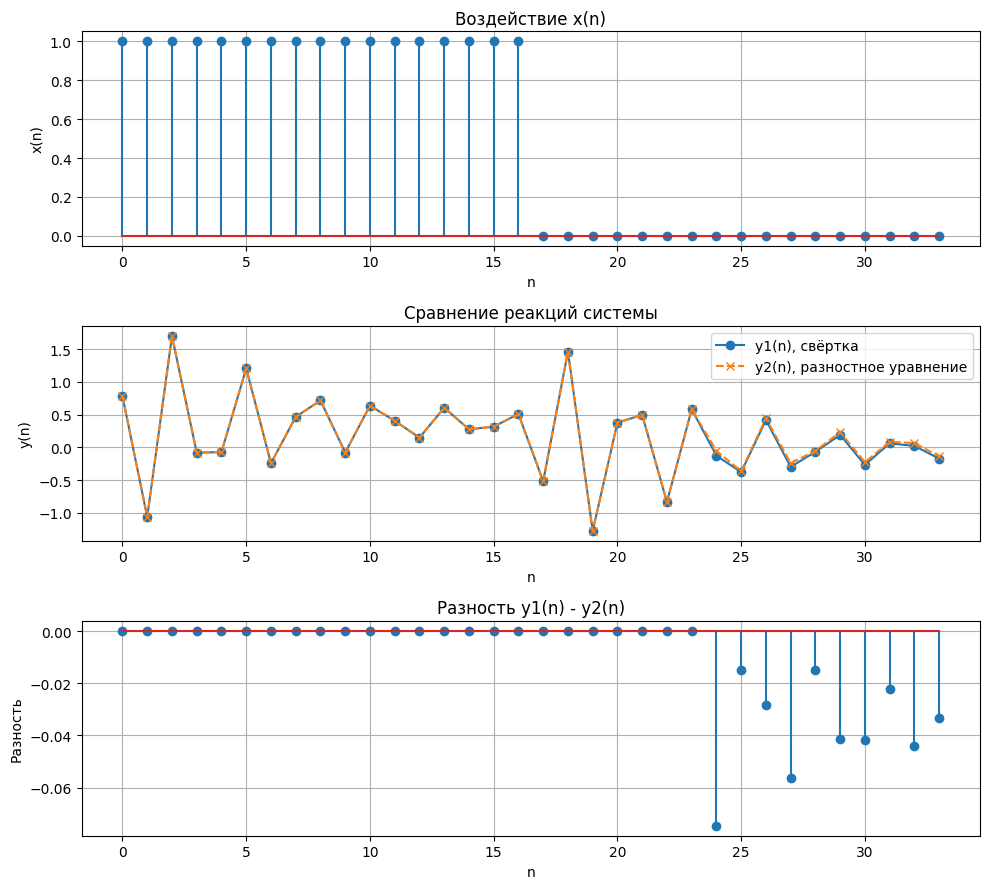

In [26]:
import numpy as np
import matplotlib.pyplot as plt

b = np.array([0.78, -0.960492, 1.248], dtype=float)
a = np.array([1.0, 1.1278, 0.724], dtype=float)
N1 = 24
N2 = 34

pulse_length = int(N2 / 2 + 0.5)
x = np.zeros(N2)
x[:pulse_length] = 1.0
h_short = np.zeros(N1)
for n in range(N1):
    value = b[n] if n < len(b) else 0.0
    for k in (1, 2):
        if n - k >= 0:
            value -= a[k] * h_short[n - k]
    h_short[n] = value / a[0]

y1_full = np.convolve(x, h_short)
y1 = y1_full[:N2]

y2 = np.zeros(N2)
for n in range(N2):
    input_part = sum(b[k] * x[n - k] for k in range(len(b)) if n - k >= 0)
    feedback = sum(a[k] * y2[n - k] for k in (1, 2) if n - k >= 0)
    y2[n] = (input_part - feedback) / a[0]

difference = y1 - y2
print(" n       y1(n)          y2(n)       y1(n)-y2(n)")
for n in range(N2):
    print(f"{n:2d}  {y1[n]: .10f}  {y2[n]: .10f}  {difference[n]: .10f}")

fig, axes = plt.subplots(3, 1, figsize=(10, 9))
axes[0].stem(range(N2), x)
axes[0].set_title("Воздействие x(n)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("x(n)")
axes[0].grid(True)

axes[1].plot(range(N2), y1, "o-", label="y1(n), свёртка")
axes[1].plot(range(N2), y2, "x--", label="y2(n), разностное уравнение")
axes[1].set_title("Сравнение реакций системы")
axes[1].set_xlabel("n")
axes[1].set_ylabel("y(n)")
axes[1].legend()
axes[1].grid(True)

axes[2].stem(range(N2), difference)
axes[2].set_title("Разность y1(n) - y2(n)")
axes[2].set_xlabel("n")
axes[2].set_ylabel("Разность")
axes[2].grid(True)

plt.tight_layout()
plt.show()

##### Анализ результата

**Разностное уравнение рекурсивного звена 2-го порядка**

С учётом рассчитанных коэффициентов разностное уравнение имеет вид:

$$
y_2(n) = 0.78x(n) - 0.960492x(n-1) + 1.248x(n-2) - 1.1278y_2(n-1) - 0.724y_2(n-2).
$$

**Длины воздействия и реакции**

- **Длина воздействия:** входная последовательность $x(n)$ имеет длину $N_2=34$ отсчёта (прямоугольный импульс из пункта 2).
- **Длина реакции:** в расчёте и на графике приведены первые 34 отсчёта $y_2(n)$, то есть реакция ограничена длиной воздействия. Теоретически отклик рекурсивного звена продолжается бесконечно, но затухает.

**Сравнение реакций $y_1(n)$ и $y_2(n)$**

По графику и таблице разности видно, что реакции, найденные свёрткой и разностным уравнением, совпадают на отсчётах $n=0,\ldots,23$. Начиная с $n=24$, появляется небольшое расхождение, максимальная абсолютная разность составляет около $0.074666$.

Причина расхождения в том, что в пункте 2 при вычислении $y_1(n)$ использованы только первые $N_1=24$ отсчёта импульсной характеристики $h(n)$. При вычислении первых $24$ отсчётов реакции остальные значения $h(n)$ ещё не нужны, но начиная с $n\ge24$ они уже вносят вклад в свёртку. Таким образом, $y_1(n)$ — приближение с усечённой импульсной характеристикой, а $y_2(n)$, вычисленная по разностному уравнению, — точная реакция рекурсивного звена, что и приводит к небольшим расхождениям.

#### Пункт 4. Нули и полюсы передаточной функции

Нули находятся как корни числителя передаточной функции, а полюсы — как корни её знаменателя. В коде ниже вычисляются их алгебраические координаты, модули и аргументы, затем корни записываются в показательной форме.

In [27]:
import numpy as np

b_coefficients = np.array([0.78, -0.960492, 1.248], dtype=float)
a_coefficients = np.array([1.0, 1.1278, 0.724], dtype=float)

zeros = np.roots(b_coefficients)
poles = np.roots(a_coefficients)
zeros = sorted(zeros, key=lambda root: root.imag, reverse=True)
poles = sorted(poles, key=lambda root: root.imag, reverse=True)

print("Нули:")
for index, root in enumerate(zeros, start=1):
    radius = abs(root)
    angle = np.angle(root)
    print(f"z{index} = {root.real:.12f} {root.imag:+.12f}j")
    print(f"Модуль z{index} = {radius:.12f}")
    print(f"Аргумент z{index} = {angle:.12f} рад = {angle / np.pi:.12f}π\n")

print("\nПолюсы:")
for index, root in enumerate(poles, start=1):
    radius = abs(root)
    angle = np.angle(root)
    print(f"p{index} = {root.real:.12f} {root.imag:+.12f}j")
    print(f"Модуль p{index} = {radius:.12f}")
    print(f"Аргумент p{index} = {angle:.12f} рад = {angle / np.pi:.12f}π\n")

assert np.allclose(np.poly(zeros), b_coefficients / b_coefficients[0])
assert np.allclose(np.poly(poles), a_coefficients / a_coefficients[0])

Нули:
z1 = 0.615700000000 +1.104949550885j
Модуль z1 = 1.264911064067
Аргумент z1 = 1.062426826607 рад = 0.338180962256π

z2 = 0.615700000000 -1.104949550885j
Модуль z2 = 1.264911064067
Аргумент z2 = -1.062426826607 рад = -0.338180962256π


Полюсы:
p1 = -0.563900000000 +0.637194467961j
Модуль p1 = 0.850881895447
Аргумент p1 = 2.295247000792 рад = 0.730599811586π

p2 = -0.563900000000 -0.637194467961j
Модуль p2 = 0.850881895447
Аргумент p2 = -2.295247000792 рад = -0.730599811586π



##### Анализ результата

**Уравнения для вычисления корней**

Исходная передаточная функция задана в степенях $z^{-1}$. Умножая числитель и знаменатель на $z^2$, получаем полиномы по $z$:

$$
0.78z^2-0.960492z+1.248=0 \quad \text{(нули)}
$$

$$
z^2+1.1278z+0.724=0 \quad \text{(полюсы)}
$$

**Нули: алгебраическая и показательная формы**

$$
z_1=0.6157+j1.104950 \approx 1.264911e^{j0.338181\pi}
$$

$$
z_2=0.6157-j1.104950 \approx 1.264911e^{-j0.338181\pi}
$$

Аргументы нулей: $\arg z_1\approx0.338181\pi$, $\arg z_2\approx-0.338181\pi$.

**Полюсы: алгебраическая и показательная формы**

$$
p_1=-0.5639+j0.637194 \approx 0.850882e^{j0.730600\pi}
$$

$$
p_2=-0.5639-j0.637194 \approx 0.850882e^{-j0.730600\pi}
$$

Аргументы полюсов: $\arg p_1\approx0.730600\pi$, $\arg p_2\approx-0.730600\pi$.

**Передаточная функция в виде произведения множителей**

Используя найденные нули и полюсы в показательной форме, получаем:

$$
H(z)=0.78\frac{\left(1-1.264911e^{j0.338181\pi}z^{-1}\right)\left(1-1.264911e^{-j0.338181\pi}z^{-1}\right)}{\left(1-0.850882e^{j0.730600\pi}z^{-1}\right)\left(1-0.850882e^{-j0.730600\pi}z^{-1}\right)}
$$

#### Пункт 5. Карта нулей и полюсов

На комплексной плоскости строится карта нулей и полюсов передаточной функции. Нули отмечаются кружками, полюсы — крестиками.

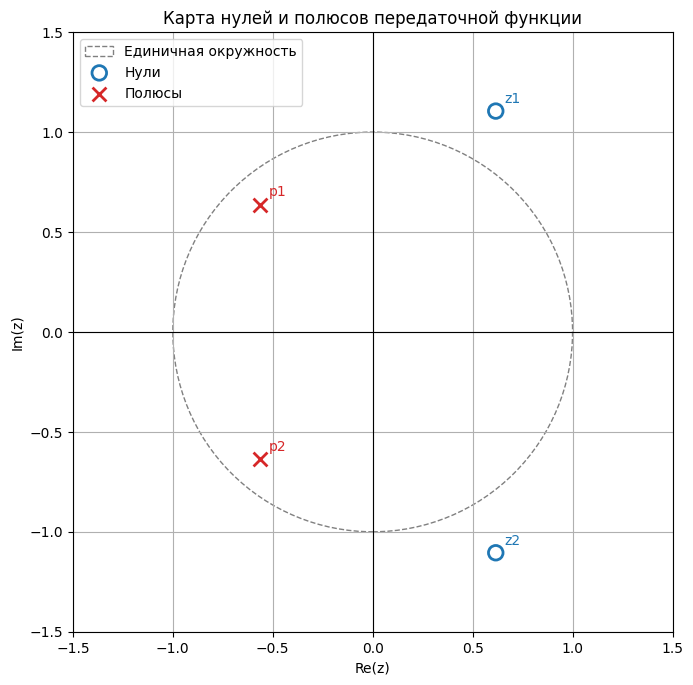

Модули полюсов: 0.850881895447, 0.850881895447


In [28]:
import numpy as np
import matplotlib.pyplot as plt

b_coefficients = np.array([0.78, -0.960492, 1.248], dtype=float)
a_coefficients = np.array([1.0, 1.1278, 0.724], dtype=float)
zeros = np.roots(b_coefficients)
poles = np.roots(a_coefficients)

fig, ax = plt.subplots(figsize=(7, 7))
unit_circle = plt.Circle((0, 0), 1, color="gray", fill=False, linestyle="--", label="Единичная окружность")
ax.add_patch(unit_circle)
ax.scatter(zeros.real, zeros.imag, marker="o", facecolors="none", edgecolors="tab:blue", s=110, linewidths=2, label="Нули")
ax.scatter(poles.real, poles.imag, marker="x", color="tab:red", s=100, linewidths=2, label="Полюсы")

for index, root in enumerate(zeros, start=1):
    ax.annotate(f"z{index}", (root.real, root.imag), xytext=(6, 6), textcoords="offset points", color="tab:blue")
for index, root in enumerate(poles, start=1):
    ax.annotate(f"p{index}", (root.real, root.imag), xytext=(6, 6), textcoords="offset points", color="tab:red")

ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_xlabel("Re(z)")
ax.set_ylabel("Im(z)")
ax.set_title("Карта нулей и полюсов передаточной функции")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

pole_radii = np.abs(poles)
stable = np.all(pole_radii < 1)
print("Модули полюсов:", ", ".join(f"{radius:.12f}" for radius in pole_radii))

##### Анализ результата

**a) Устойчивость рекурсивного звена**

На карте оба полюса расположены внутри единичной окружности. Их модули равны примерно $0.850882$, то есть меньше единицы. Следовательно, рекурсивное звено является устойчивым.

**b) Сравнение с нулями и полюсами из пункта 4**

Координаты маркеров на карте совпадают с рассчитанными в пункте 4 значениями: нули $0.6157\pm j1.104950$, полюса $-0.5639\pm j0.637194$.

#### Пункт 6. АЧХ и ФЧХ в шкале нормированных частот

Вычислим частотную характеристику передаточной функции на основной полосе нормированных угловых частот и построим графики её модуля и фазы.

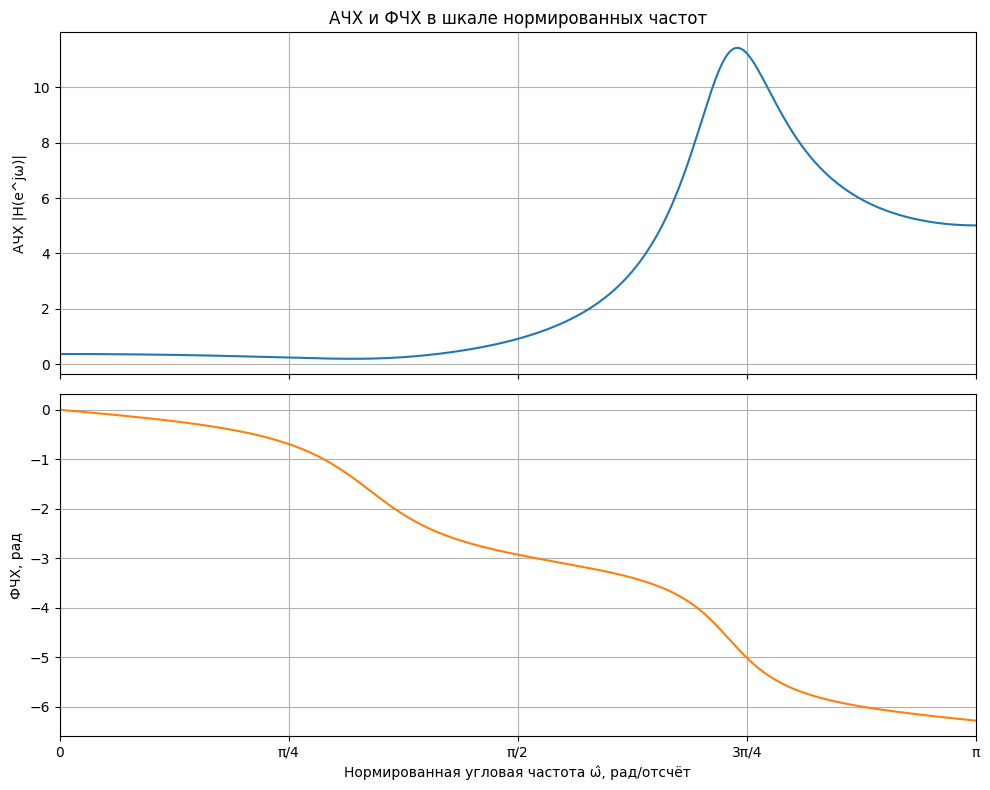

Минимум АЧХ: 0.200894 при ω̂/π = 0.319980
Максимум АЧХ: 11.416589 при ω̂/π = 0.739619


In [29]:
import numpy as np
import matplotlib.pyplot as plt

b_frequency = np.array([0.78, -0.960492, 1.248], dtype=float)
a_frequency = np.array([1.0, 1.1278, 0.724], dtype=float)
omega_hat = np.linspace(0, np.pi, 2048)
z_inverse = np.exp(-1j * omega_hat)
H_frequency = (
    b_frequency[0] + b_frequency[1] * z_inverse + b_frequency[2] * z_inverse**2
) / (
    a_frequency[0] + a_frequency[1] * z_inverse + a_frequency[2] * z_inverse**2
)
amplitude_response = np.abs(H_frequency)
phase_response = np.unwrap(np.angle(H_frequency))

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].plot(omega_hat, amplitude_response, color="tab:blue")
axes[0].set_ylabel("АЧХ |H(e^jω)|")
axes[0].set_title("АЧХ и ФЧХ в шкале нормированных частот")
axes[0].grid(True)

axes[1].plot(omega_hat, phase_response, color="tab:orange")
axes[1].set_xlabel("Нормированная угловая частота ω̂, рад/отсчёт")
axes[1].set_ylabel("ФЧХ, рад")
axes[1].grid(True)
axes[1].set_xticks(
    np.linspace(0, np.pi, 5), ["0", "π/4", "π/2", "3π/4", "π"]
)
axes[1].set_xlim(0, np.pi)
plt.tight_layout()
plt.show()

minimum_index = np.argmin(amplitude_response)
maximum_index = np.argmax(amplitude_response)
print(
    f"Минимум АЧХ: {amplitude_response[minimum_index]:.6f} "
    f"при ω̂/π = {omega_hat[minimum_index] / np.pi:.6f}"
)
print(
    f"Максимум АЧХ: {amplitude_response[maximum_index]:.6f} "
    f"при ω̂/π = {omega_hat[maximum_index] / np.pi:.6f}"
)
assert np.all(np.isfinite(H_frequency))

##### Анализ результата

**a) Основная полоса частот**

Для одностороннего графика основной полосой является интервал $0\leqslant\hat{\omega}\leqslant\pi$ рад/отсчёт. Частотная характеристика периодична с периодом $2\pi$, для вещественных коэффициентов её амплитуда симметрична относительно нулевой частоты.

**b) Связь карты нулей и полюсов с АЧХ**

Нули имеют аргументы $\pm0.338181\pi$, рядом с этой областью на АЧХ наблюдается провал. Минимум на построенной сетке составляет примерно $0.201$ при $\hat{\omega}\approx0.3197\pi$. Поскольку нули находятся вне единичной окружности, АЧХ не обращается в ноль. Полюсы с аргументами $\pm0.730600\pi$ расположены внутри единичной окружности и создают выраженный резонансный максимум: примерно $11.417$ при $\hat{\omega}\approx0.7396\pi$.

**c) Скачок фазы и значение АЧХ**

Истинного скачка фазы на $\pi$, соответствующего нулевому значению АЧХ, здесь нет: нули не лежат на единичной окружности, поэтому $|H(e^{j\hat{\omega}})|$ остаётся ненулевой.

**d) Подавление частотных составляющих воздействия**

В низкочастотной области АЧХ меньше единицы, поэтому низкие частотные составляющие воздействия преимущественно ослабляются. На высоких частотах около резонансного максимума АЧХ значительно больше единицы, поэтому эти составляющие усиливаются.

#### Пункт 7. АЧХ и ФЧХ в шкале частот (Гц)

Частота дискретизации равна $f_{д}=14000$ Гц. Построим амплитудную и фазовую характеристики на основной полосе частот.

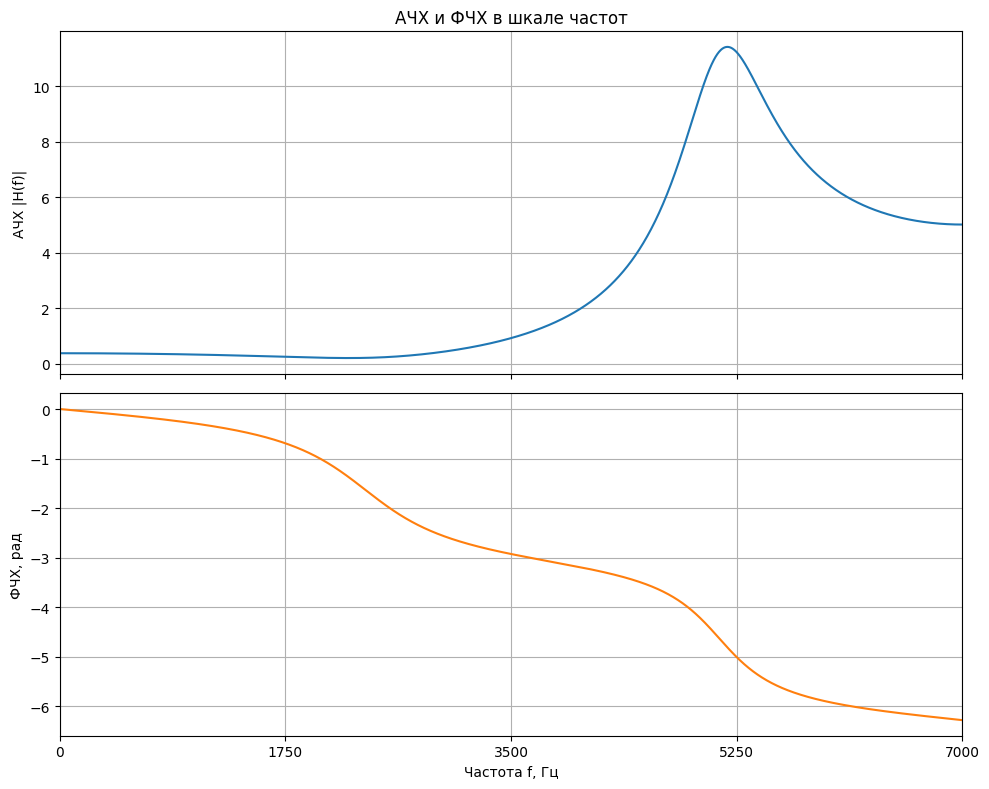

Минимум АЧХ: 0.200894 при f = 2239.86 Гц
Максимум АЧХ: 11.416589 при f = 5177.33 Гц


In [30]:
import numpy as np
import matplotlib.pyplot as plt

b_hz = np.array([0.78, -0.960492, 1.248], dtype=float)
a_hz = np.array([1.0, 1.1278, 0.724], dtype=float)
f_d = 14000.0
frequency_hz = np.linspace(0, f_d / 2, 2048)
omega_hat_hz = 2 * np.pi * frequency_hz / f_d
z_inverse_hz = np.exp(-1j * omega_hat_hz)
H_frequency_hz = (
    b_hz[0] + b_hz[1] * z_inverse_hz + b_hz[2] * z_inverse_hz**2
) / (
    a_hz[0] + a_hz[1] * z_inverse_hz + a_hz[2] * z_inverse_hz**2
)
amplitude_response_hz = np.abs(H_frequency_hz)
phase_response_hz = np.unwrap(np.angle(H_frequency_hz))

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].plot(frequency_hz, amplitude_response_hz, color="tab:blue")
axes[0].set_ylabel("АЧХ |H(f)|")
axes[0].set_title("АЧХ и ФЧХ в шкале частот")
axes[0].grid(True)

axes[1].plot(frequency_hz, phase_response_hz, color="tab:orange")
axes[1].set_xlabel("Частота f, Гц")
axes[1].set_ylabel("ФЧХ, рад")
axes[1].grid(True)
frequency_ticks = np.linspace(0, f_d / 2, 5)
axes[1].set_xticks(frequency_ticks, [f"{tick:.0f}" for tick in frequency_ticks])
axes[1].set_xlim(0, f_d / 2)
plt.tight_layout()
plt.show()

minimum_index_hz = np.argmin(amplitude_response_hz)
maximum_index_hz = np.argmax(amplitude_response_hz)
print(
    f"Минимум АЧХ: {amplitude_response_hz[minimum_index_hz]:.6f} "
    f"при f = {frequency_hz[minimum_index_hz]:.2f} Гц"
)
print(
    f"Максимум АЧХ: {amplitude_response_hz[maximum_index_hz]:.6f} "
    f"при f = {frequency_hz[maximum_index_hz]:.2f} Гц"
)
assert np.all(np.isfinite(H_frequency_hz))

##### Анализ результата

**a) Границы основной полосы частот**

При $f_{д}=14000$ Гц основная односторонняя полоса составляет $0\leqslant f\leqslant f_{д}/2$, то есть от $0$ до $7000$ Гц. Частоты выше частоты Найквиста не входят в эту полосу, поскольку спектр дискретного сигнала периодичен.

**b) Соответствие нормированной частоты и частоты в герцах**

Нормированная угловая частота связана с частотой в герцах формулой $\hat{\omega}=2\pi f/f_{д}$. Обратный пересчёт: $f=\hat{\omega}f_{д}/(2\pi)$. Поэтому границы $0\ldots\pi$ рад/отсчёт соответствуют границам $0\ldots7000$ Гц. Форма АЧХ и ФЧХ не меняется — меняется только горизонтальный масштаб.

Для данного варианта минимум АЧХ на расчётной сетке составляет примерно $0.201$ при $f\approx2239.86$ Гц, а максимум — примерно $11.417$ при $f\approx5177.33$ Гц. Эти значения согласуются с графиками пункта 6 после пересчёта частот.

### Часть 2

#### Пункт 1. Последовательность на периоде $N$

При $A_1=1.14$, $A_2=2.28$, $f_1=1250$ Гц, $f_2=1875$ Гц и $T=0.0001$ с формула последовательности принимает вид:

$$
x(nT)=1.14\cos\left(\frac{\pi}{4}n+\frac{\pi}{4}\right)+2.28\cos\left(\frac{3\pi}{8}n+\frac{\pi}{8}\right),\quad n=0,1,\ldots,63.
$$

Построим графики последовательности на $N=64$ отсчётах в шкалах дискретного времени $n$ и нормированного дискретного времени $\hat{n}=n/N$.

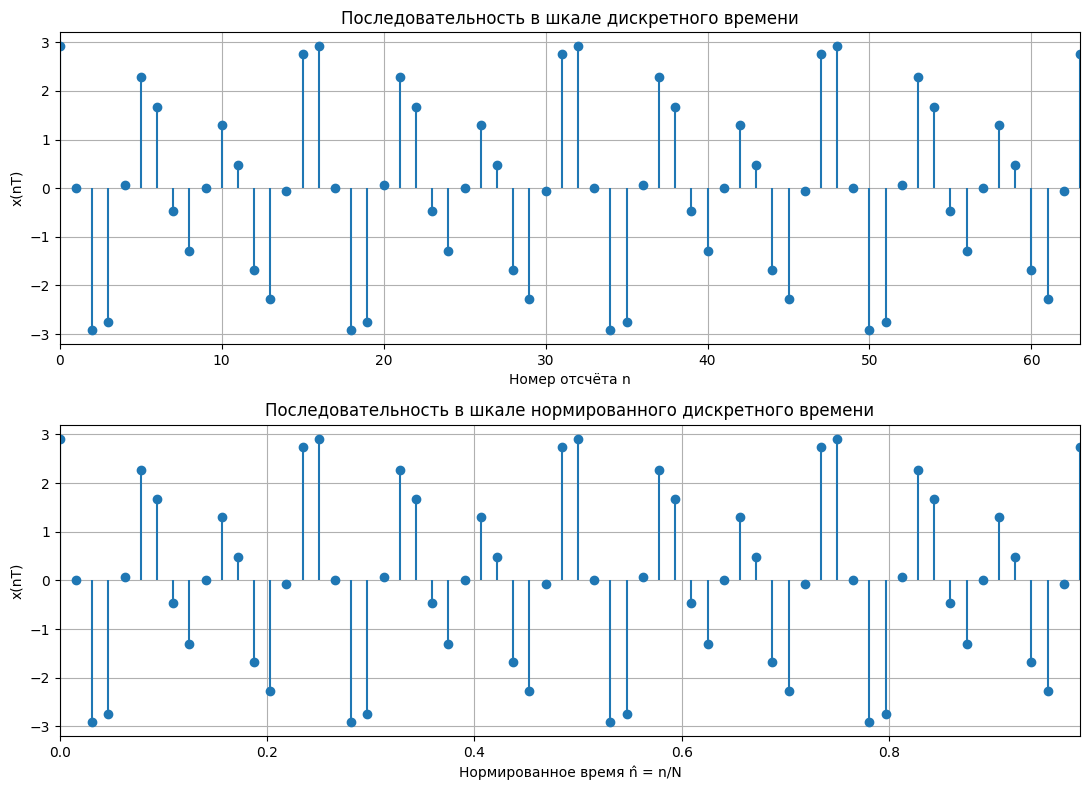

Периоды составляющих: 8 и 16 отсчётов
Основной период суммы: 16 отсчётов
Диапазон отсчётов: от -2.912547 до 2.912547


In [31]:
import numpy as np
import matplotlib.pyplot as plt

N = 64
f_d_part2 = 10000.0
T = 1 / f_d_part2
A1 = 1.14
A2 = 2.28
f1 = 1250.0
f2 = 1875.0

n_part2 = np.arange(N)
t_part2 = n_part2 * T
n_normalized = n_part2 / N
x_part2 = (
    A1 * np.cos(2 * np.pi * f1 * t_part2 + np.pi / 4)
    + A2 * np.cos(2 * np.pi * f2 * t_part2 + np.pi / 8)
)

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
axes[0].stem(n_part2, x_part2, basefmt=" ")
axes[0].set_title("Последовательность в шкале дискретного времени")
axes[0].set_xlabel("Номер отсчёта n")
axes[0].set_ylabel("x(nT)")
axes[0].set_xlim(0, N - 1)
axes[0].grid(True)

axes[1].stem(n_normalized, x_part2, basefmt=" ")
axes[1].set_title("Последовательность в шкале нормированного дискретного времени")
axes[1].set_xlabel("Нормированное время n̂ = n/N")
axes[1].set_ylabel("x(nT)")
axes[1].set_xlim(0, (N - 1) / N)
axes[1].grid(True)
plt.tight_layout()
plt.show()

period_f1 = int(f_d_part2 / np.gcd(int(f1), int(f_d_part2)))
period_f2 = int(f_d_part2 / np.gcd(int(f2), int(f_d_part2)))
signal_period = int(np.lcm(period_f1, period_f2))
print(f"Периоды составляющих: {period_f1} и {period_f2} отсчётов")
print(f"Основной период суммы: {signal_period} отсчётов")
print(f"Диапазон отсчётов: от {x_part2.min():.6f} до {x_part2.max():.6f}")
assert np.all(np.isfinite(x_part2))
assert np.allclose(x_part2[:-signal_period], x_part2[signal_period:])

#### Пункт 2. Обратное дискретное преобразование Фурье

Вычислим ДПФ последовательности $x(n)$ из пункта 1, затем применим обратное ДПФ и построим восстановленную последовательность в шкале нормированного дискретного времени $\hat{n}=n/N$:

$$
X(k)=\sum_{n=0}^{N-1}x(n)e^{-j2\pi kn/N},\qquad
x_{\text{восст}}(n)=\frac{1}{N}\sum_{k=0}^{N-1}X(k)e^{j2\pi kn/N}.
$$

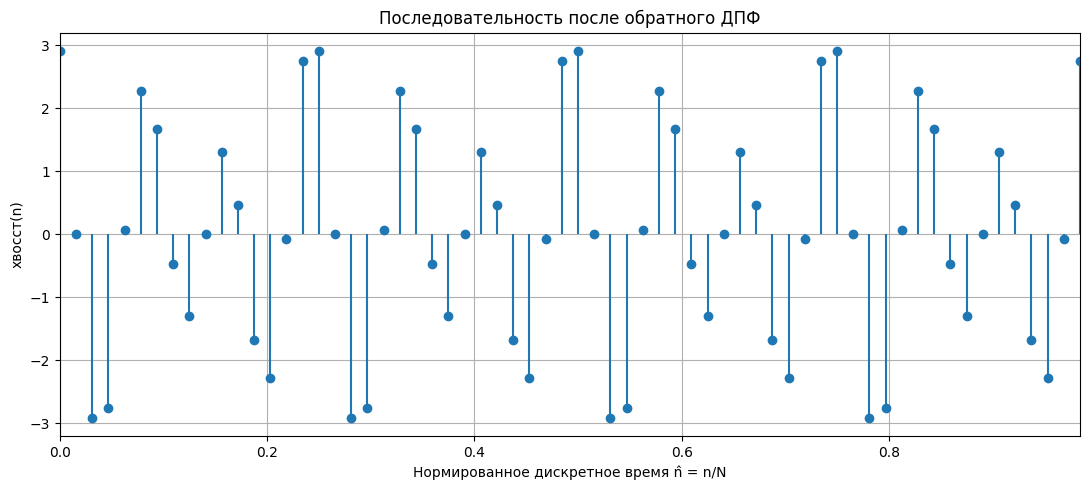

Максимальная ошибка восстановления: 8.882e-16


In [32]:
import numpy as np
import matplotlib.pyplot as plt

spectrum_part2 = np.fft.fft(x_part2)
x_reconstructed = np.fft.ifft(spectrum_part2)
reconstruction_error = np.max(np.abs(x_reconstructed.real - x_part2))
imaginary_residual = np.max(np.abs(x_reconstructed.imag))

fig, ax = plt.subplots(figsize=(11, 5))
ax.stem(n_normalized, x_reconstructed.real, basefmt=" ")
ax.set_title("Последовательность после обратного ДПФ")
ax.set_xlabel("Нормированное дискретное время n̂ = n/N")
ax.set_ylabel("xвосст(n)")
ax.set_xlim(0, (N - 1) / N)
ax.grid(True)
plt.tight_layout()
plt.show()

print(f"Максимальная ошибка восстановления: {reconstruction_error:.3e}")
assert np.allclose(x_reconstructed.real, x_part2, atol=1e-12)

#### Пункт 3. Амплитудный и фазовый спектры

Вычислим ДПФ последовательности из пункта 1 и построим односторонние амплитудный и фазовый спектры: в нормированной угловой частоте $\hat{\omega}$ и в абсолютной частоте $f$ (Гц).

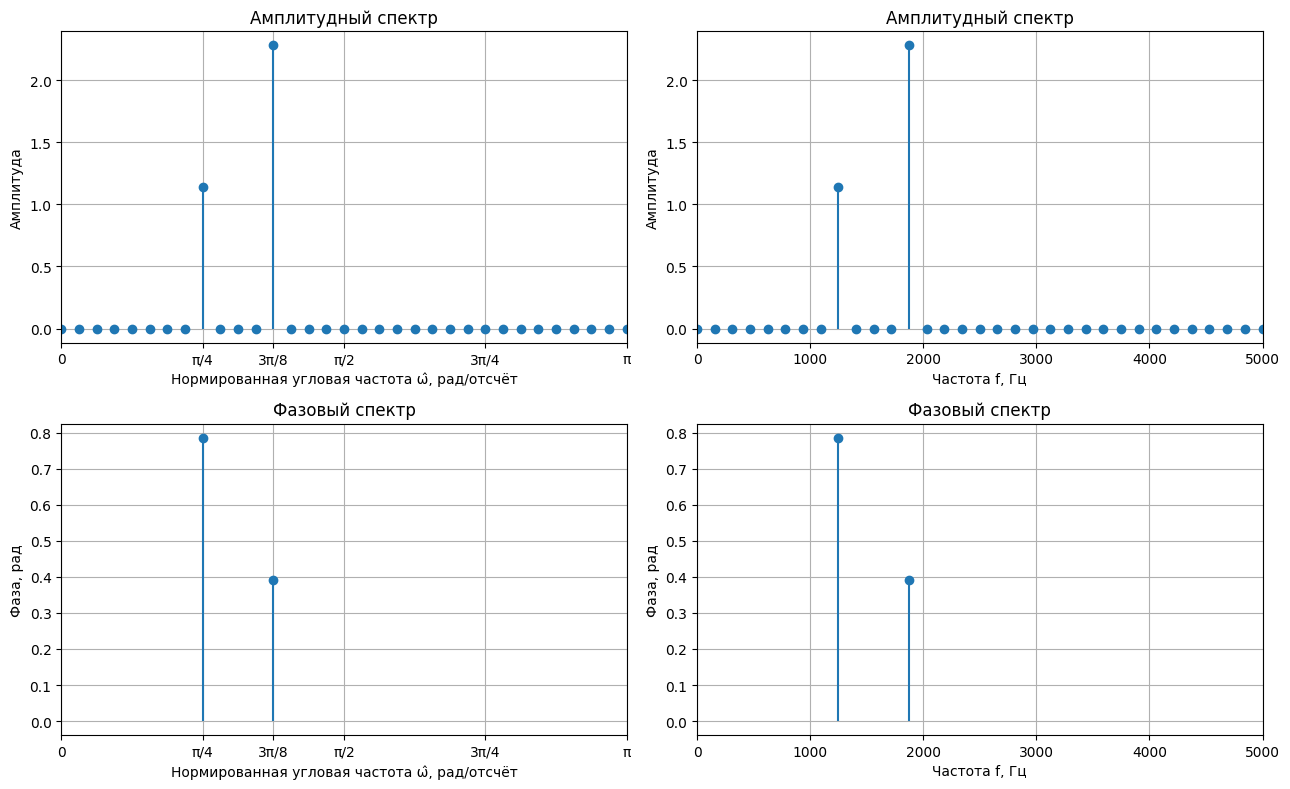

In [33]:
import numpy as np
import matplotlib.pyplot as plt

spectrum_part2 = np.fft.fft(x_part2)
frequency_bins = np.arange(N // 2 + 1)
normalized_frequency = 2 * np.pi * frequency_bins / N
absolute_frequency = frequency_bins * f_d_part2 / N

amplitude_spectrum = np.abs(spectrum_part2[:N // 2 + 1]) / N
amplitude_spectrum[1:-1] *= 2
phase_spectrum = np.angle(spectrum_part2[:N // 2 + 1])
phase_mask = amplitude_spectrum > 1e-10
phase_to_plot = np.where(phase_mask, phase_spectrum, np.nan)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].stem(normalized_frequency, amplitude_spectrum, basefmt=" ")
axes[0, 0].set_title("Амплитудный спектр")
axes[0, 0].set_xlabel("Нормированная угловая частота ω̂, рад/отсчёт")
axes[0, 0].set_ylabel("Амплитуда")
axes[0, 0].grid(True)

axes[1, 0].stem(normalized_frequency, phase_to_plot, basefmt=" ")
axes[1, 0].set_title("Фазовый спектр")
axes[1, 0].set_xlabel("Нормированная угловая частота ω̂, рад/отсчёт")
axes[1, 0].set_ylabel("Фаза, рад")
axes[1, 0].grid(True)

axes[0, 1].stem(absolute_frequency, amplitude_spectrum, basefmt=" ")
axes[0, 1].set_title("Амплитудный спектр")
axes[0, 1].set_xlabel("Частота f, Гц")
axes[0, 1].set_ylabel("Амплитуда")
axes[0, 1].grid(True)

axes[1, 1].stem(absolute_frequency, phase_to_plot, basefmt=" ")
axes[1, 1].set_title("Фазовый спектр")
axes[1, 1].set_xlabel("Частота f, Гц")
axes[1, 1].set_ylabel("Фаза, рад")
axes[1, 1].grid(True)

for ax in (axes[0, 0], axes[1, 0]):
    ax.set_xlim(0, np.pi)
    ax.set_xticks(
        [0, np.pi / 4, 3 * np.pi / 8, np.pi / 2, 3 * np.pi / 4, np.pi],
        ["0", "π/4", "3π/8", "π/2", "3π/4", "π"],
    )
for ax in (axes[0, 1], axes[1, 1]):
    ax.set_xlim(0, f_d_part2 / 2)

plt.tight_layout()
plt.show()

significant_bins = np.flatnonzero(phase_mask)

assert np.array_equal(significant_bins, np.array([8, 12]))
assert np.allclose(amplitude_spectrum[significant_bins], [A1, A2])
assert np.allclose(phase_spectrum[significant_bins], [np.pi / 4, np.pi / 8])

##### Анализ результата

**a) Связь дискретного нормированного времени с дискретным временем**

Нормированное дискретное время задаётся как $\hat{n}=n/N$. При переходе от номера отсчёта $n$ к $\hat{n}$ отсчётам меняется только горизонтальный масштаб графика: последовательность и её значения остаются теми же. Для данного сигнала $N=64$, поэтому шаг нормированной временной шкалы равен $1/64$.

**b) Связь частоты в герцах с нормированной частотой**

Связь частот задаётся формулой $\hat{\omega}=2\pi f/f_{д}$, где $f_{д}=10000$ Гц. Обратно, $f=\hat{\omega}f_{д}/(2\pi)$. Поэтому частоте $f_1=1250$ Гц соответствует $\hat{\omega}_1=\pi/4$, а частоте $f_2=1875$ Гц соответствует $\hat{\omega}_2=3\pi/8$.

**c) Вид амплитудного и фазового спектров**

В одностороннем амплитудном спектре находятся два ненулевых пика: амплитуда $1.14$ при $1250$ Гц ($\hat{\omega}=\pi/4$) и амплитуда $2.28$ при $1875$ Гц ($\hat{\omega}=3\pi/8$). Эти компоненты точно попадают в узлы ДПФ, поэтому спектральная утечка отсутствует. Фазы соответствующих положительных частот равны $\pi/4$ и $\pi/8$ рад.

#### Пункт 4. Модуль ДПФ конечной последовательности и амплитудный спектр периодического аналога

Вычислим ДПФ блока $x(n)$ длины $N=64$ и построим в общей шкале нормированных частот модуль ДПФ $|X(k)|$ и амплитудный спектр периодического продолжения. Коэффициенты ряда Фурье периодического аналога равны $C(k)=X(k)/N$, поэтому его двусторонний амплитудный спектр задаётся как $|C(k)|=|X(k)|/N$.

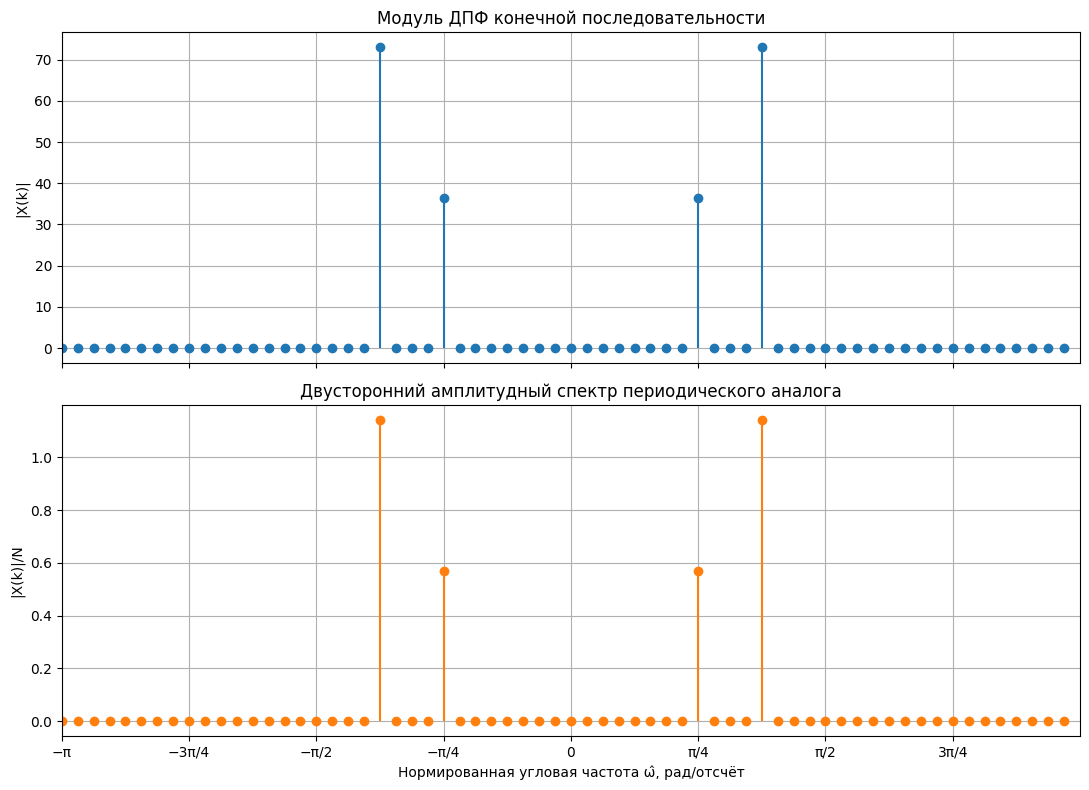

Ненулевые частотные отсчёты ДПФ: [-12  -8   8  12]
Модули ДПФ в этих отсчётах: [72.96 36.48 36.48 72.96]
Амплитуды коэффициентов периодического ряда: [1.14 0.57 0.57 1.14]


In [34]:
import numpy as np
import matplotlib.pyplot as plt

dft_finite = np.fft.fft(x_part2)
dft_centered = np.fft.fftshift(dft_finite)
frequency_bins_centered = np.fft.fftshift(np.fft.fftfreq(N) * N).astype(int)
normalized_frequency_centered = 2 * np.pi * frequency_bins_centered / N
dft_magnitude = np.abs(dft_centered)
periodic_amplitude_spectrum = dft_magnitude / N

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
axes[0].stem(normalized_frequency_centered, dft_magnitude, basefmt=" ")
axes[0].set_title("Модуль ДПФ конечной последовательности")
axes[0].set_ylabel("|X(k)|")
axes[0].grid(True)

axes[1].stem(
    normalized_frequency_centered,
    periodic_amplitude_spectrum,
    basefmt=" ",
    linefmt="C1-",
    markerfmt="C1o",
)
axes[1].set_title("Двусторонний амплитудный спектр периодического аналога")
axes[1].set_xlabel("Нормированная угловая частота ω̂, рад/отсчёт")
axes[1].set_ylabel("|X(k)|/N")
axes[1].grid(True)
axes[1].set_xlim(-np.pi, np.pi)
axes[1].set_xticks(
    [-np.pi, -3 * np.pi / 4, -np.pi / 2, -np.pi / 4, 0,
     np.pi / 4, np.pi / 2, 3 * np.pi / 4],
    ["−π", "−3π/4", "−π/2", "−π/4", "0", "π/4", "π/2", "3π/4"],
)
plt.tight_layout()
plt.show()

nonzero_bins = np.flatnonzero(periodic_amplitude_spectrum > 1e-10)
print("Ненулевые частотные отсчёты ДПФ:", frequency_bins_centered[nonzero_bins])
print(
    "Модули ДПФ в этих отсчётах:",
    np.round(dft_magnitude[nonzero_bins], 6),
)
print(
    "Амплитуды коэффициентов периодического ряда:",
    np.round(periodic_amplitude_spectrum[nonzero_bins], 6),
)
assert np.array_equal(frequency_bins_centered[nonzero_bins], [-12, -8, 8, 12])
assert np.allclose(dft_magnitude, N * periodic_amplitude_spectrum)
assert np.allclose(
    periodic_amplitude_spectrum[nonzero_bins], [A2 / 2, A1 / 2, A1 / 2, A2 / 2]
)

##### Анализ результата

**Связь модуля ДПФ с амплитудным спектром периодической последовательности**

Для периодического продолжения блока длины $N$ коэффициенты ряда Фурье равны $C(k)=X(k)/N$. Поэтому амплитудный спектр этих коэффициентов получается делением модуля ДПФ на $N$: $|C(k)|=|X(k)|/N$. На построенных графиках частоты пиков совпадают, а их значения различаются в $N=64$ раз.

У последовательности ненулевые компоненты находятся на частотных отсчётах с индексами $k=\pm8$ и $k=\pm12$. Модуль ДПФ в них равен соответственно $36.48$ и $72.96$, а модули коэффициентов ряда периодического аналога — $0.57$ и $1.14$ для каждой пары положительной и отрицательной частот.

#### Пункт 5. Восстановление периодического аналогового сигнала

Восстановим сигнал по ДПФ $X(k)$ на интервале $0\leqslant t\leqslant(N-1)T$ с шагом $\Delta t=0.25T$. Используем заданное в условии представление:

$$
x(t)=\frac{1}{N}\sum_{k=-N/2}^{N/2-1}X_a(k)\exp\left(j\frac{2\pi k t}{NT}\right),
\qquad
X_a(k)=\begin{cases}X(N+k),&-N/2\leqslant k<0\\X(k),&0\leqslant k\leqslant N/2-1.\end{cases}
$$

Также построим графики исходной последовательности и модуля её ДПФ, восстановленного сигнала и его амплитудного спектра, а также исходного аналогового сигнала.

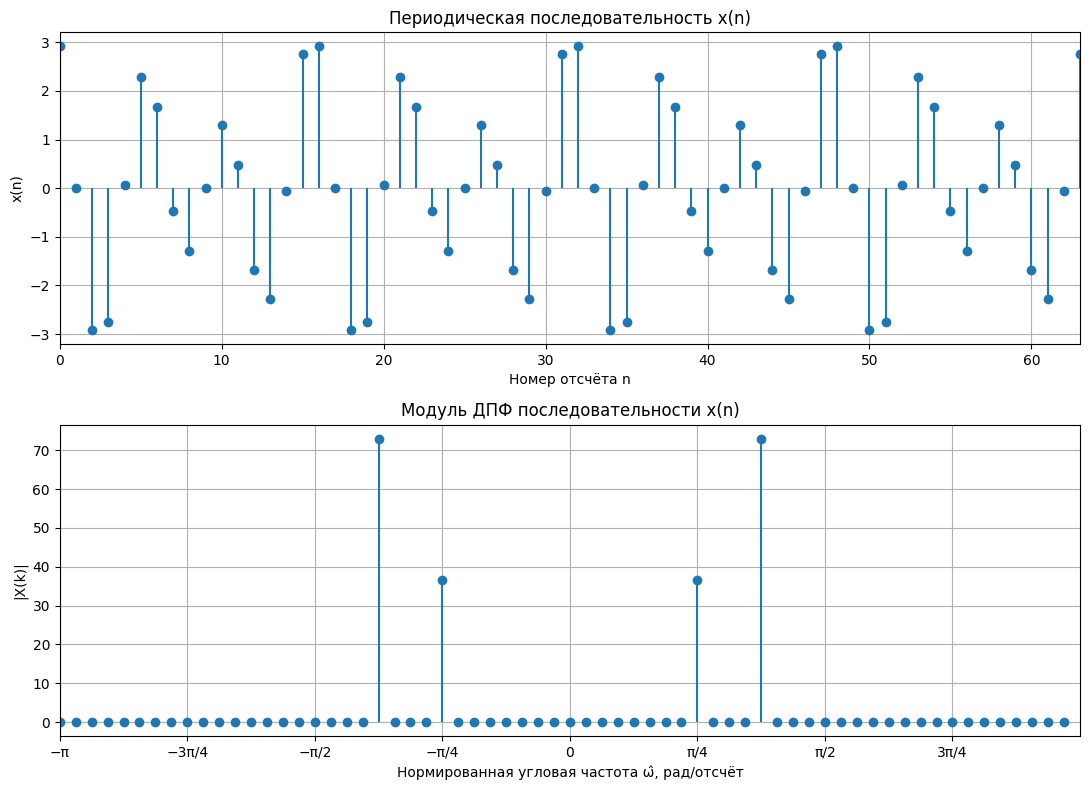

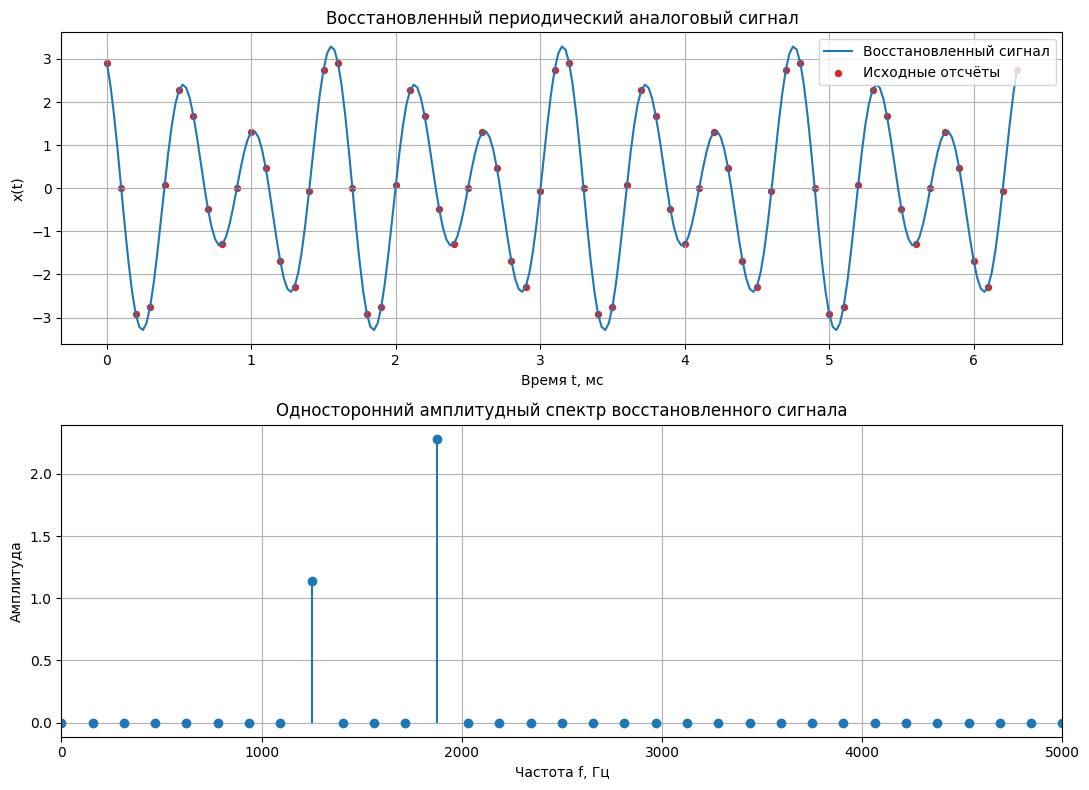

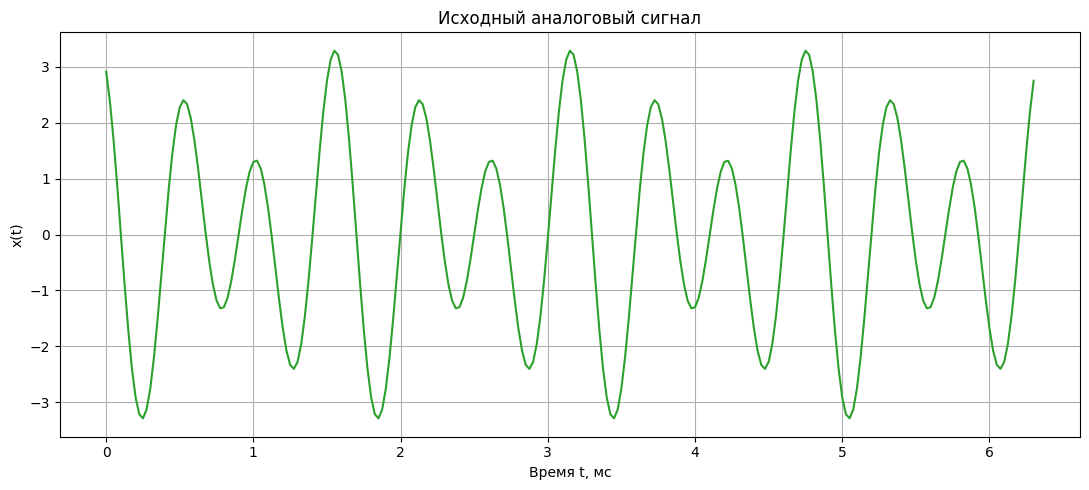

Максимальная ошибка восстановления: 4.236e-14


In [35]:
import numpy as np
import matplotlib.pyplot as plt

N = 64
f_d_part2 = 10000.0
T = 1 / f_d_part2
A1 = 1.14
A2 = 2.28
f1 = 1250.0
f2 = 1875.0

n_reconstruction = np.arange(N)
t_samples = n_reconstruction * T
x_samples = (
    A1 * np.cos(2 * np.pi * f1 * t_samples + np.pi / 4)
    + A2 * np.cos(2 * np.pi * f2 * t_samples + np.pi / 8)
)
X_reconstruction = np.fft.fft(x_samples)

k_centered = np.fft.fftshift(np.fft.fftfreq(N) * N).astype(int)
X_a = np.fft.fftshift(X_reconstruction)
t_analog = np.arange(4 * (N - 1) + 1) * (T / 4)
reconstruction_basis = np.exp(
    1j * 2 * np.pi * t_analog[:, np.newaxis] * k_centered[np.newaxis, :] / (N * T)
)
x_reconstructed_analog = np.sum(
    reconstruction_basis * X_a[np.newaxis, :], axis=1
) / N
x_original_analog = (
    A1 * np.cos(2 * np.pi * f1 * t_analog + np.pi / 4)
    + A2 * np.cos(2 * np.pi * f2 * t_analog + np.pi / 8)
)

omega_centered = 2 * np.pi * k_centered / N
dft_magnitude_reconstruction = np.abs(X_a)

positive_bins = np.arange(N // 2 + 1)
frequency_analog = positive_bins / (N * T)
analog_amplitude_spectrum = np.abs(X_reconstruction[:N // 2 + 1]) / N
analog_amplitude_spectrum[1:-1] *= 2

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
axes[0].stem(n_reconstruction, x_samples, basefmt=" ")
axes[0].set_title("Периодическая последовательность x(n)")
axes[0].set_xlabel("Номер отсчёта n")
axes[0].set_ylabel("x(n)")
axes[0].set_xlim(0, N - 1)
axes[0].grid(True)
axes[1].stem(omega_centered, dft_magnitude_reconstruction, basefmt=" ")
axes[1].set_title("Модуль ДПФ последовательности x(n)")
axes[1].set_xlabel("Нормированная угловая частота ω̂, рад/отсчёт")
axes[1].set_ylabel("|X(k)|")
axes[1].set_xlim(-np.pi, np.pi)
axes[1].set_xticks(
    [-np.pi, -3 * np.pi / 4, -np.pi / 2, -np.pi / 4, 0,
     np.pi / 4, np.pi / 2, 3 * np.pi / 4],
    ["−π", "−3π/4", "−π/2", "−π/4", "0", "π/4", "π/2", "3π/4"],
)
axes[1].grid(True)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 8))
axes[0].plot(t_analog * 1e3, x_reconstructed_analog.real, label="Восстановленный сигнал")
axes[0].scatter(t_samples * 1e3, x_samples, s=18, color="tab:red", label="Исходные отсчёты")
axes[0].set_title("Восстановленный периодический аналоговый сигнал")
axes[0].set_xlabel("Время t, мс")
axes[0].set_ylabel("x(t)")
axes[0].grid(True)
axes[0].legend()

axes[1].stem(frequency_analog, analog_amplitude_spectrum, basefmt=" ")
axes[1].set_title("Односторонний амплитудный спектр восстановленного сигнала")
axes[1].set_xlabel("Частота f, Гц")
axes[1].set_ylabel("Амплитуда")
axes[1].set_xlim(0, f_d_part2 / 2)
axes[1].grid(True)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(t_analog * 1e3, x_original_analog, color="tab:green")
ax.set_title("Исходный аналоговый сигнал")
ax.set_xlabel("Время t, мс")
ax.set_ylabel("x(t)")
ax.grid(True)
plt.tight_layout()
plt.show()

reconstruction_error = np.max(
    np.abs(x_reconstructed_analog.real - x_original_analog)
)
imaginary_residual = np.max(np.abs(x_reconstructed_analog.imag))
print(f"Максимальная ошибка восстановления: {reconstruction_error:.3e}")
assert len(t_analog) == 4 * (N - 1) + 1
assert np.isclose(t_analog[-1], (N - 1) * T)
assert reconstruction_error < 1e-10
assert imaginary_residual < 1e-10

#### Пункт 6. Анализ результатов восстановления сигнала

По результатам пункта 5 поясним численную связь спектральных пиков и точность восстановления аналогового сигнала.

**a) Связь модуля ДПФ последовательности со спектром аналогового сигнала**

В спектре восстановленного сигнала наблюдаются гармоники на частотах $1250$ и $1875$ Гц. Они соответствуют положительным и отрицательным частотным отсчётам ДПФ $k=\pm8$ и $k=\pm12$. Для внутреннего положительного частотного отсчёта амплитуда одностороннего спектра аналогового сигнала равна $2|X(k)|/N$. Поэтому для $N=64$ получаем $2\cdot36.48/64=1.14$ при $1250$ Гц и $2\cdot72.96/64=2.28$ при $1875$ Гц — именно амплитуды двух косинусоид в восстановленном сигнале. В двустороннем спектре модуль коэффициента каждой отдельной линии равен $|X(k)|/N$, то есть половине амплитуды соответствующего косинуса.

**b) Сравнение восстановленного и исходного сигналов**

На графиках восстановленный сигнал проходит через исходные отсчёты и визуально совпадает с исходным аналоговым сигналом. Это объясняется тем, что обе гармоники точно попадают в частотные отсчёты ДПФ, а восстановление выполняется по всем коэффициентам ДПФ. Максимальное численное различие на заданном интервале составляет около $4.2\cdot10^{-14}$, то есть является погрешностью вычислений с плавающей точкой.

#### Пункт 7. Проверка равенства Парсеваля

Проверим равенство Парсеваля для последовательности, сравнив энергию в дискретной временной области с энергией её ДПФ при принятом определении преобразования:

$$
\sum_{n=0}^{N-1}|x(n)|^2=\frac{1}{N}\sum_{k=0}^{N-1}|X(k)|^2.
$$

In [36]:
import numpy as np

N = 64
f_d_part2 = 10000.0
T = 1 / f_d_part2
A1 = 1.14
A2 = 2.28
f1 = 1250.0
f2 = 1875.0
n_parseval = np.arange(N)
x_parseval = (
    A1 * np.cos(2 * np.pi * f1 * n_parseval * T + np.pi / 4)
    + A2 * np.cos(2 * np.pi * f2 * n_parseval * T + np.pi / 8)
)
X_parseval = np.fft.fft(x_parseval)

energy_time = np.sum(np.abs(x_parseval) ** 2)
energy_frequency = np.sum(np.abs(X_parseval) ** 2) / N
parseval_error = abs(energy_time - energy_frequency)
mean_square_value = energy_time / N

print(f"Энергия во временной области: {energy_time:.12f}")
print(f"Энергия по ДПФ: {energy_frequency:.12f}")
print(f"Абсолютная разность: {parseval_error:.3e}")
print(f"Среднее значение квадрата отсчётов: {mean_square_value:.12f}")
assert np.isclose(energy_time, energy_frequency, rtol=1e-12, atol=1e-12)

Энергия во временной области: 207.936000000000
Энергия по ДПФ: 207.936000000000
Абсолютная разность: 8.527e-14
Среднее значение квадрата отсчётов: 3.249000000000


##### Анализ результата

**Проверка равенства**

Энергия последовательности во временной области равна $\sum_{n=0}^{63}|x(n)|^2=207.936$. По спектральным отсчётам получаем $\frac{1}{64}\sum_{k=0}^{63}|X(k)|^2=207.936$. Абсолютное расхождение составляет около $8.5\cdot10^{-14}$ и обусловлено округлением чисел при вычислениях с плавающей точкой. Следовательно, равенство Парсеваля выполняется.

**Смысл равенства**

Равенство Парсеваля означает, что энергия конечной последовательности сохраняется при переходе из временного представления в частотное. При принятом определении ДПФ сумма квадратов модулей спектральных отсчётов содержит множитель $1/N$.

## Выводы

В ходе практической работы были исследованы линейные дискретные системы и методы частотного анализа. Для рекурсивного звена вычислены импульсная характеристика, реакции на заданное воздействие, нули, полюсы, карта корней, АЧХ и ФЧХ. Расположение полюсов внутри единичной окружности подтвердило устойчивость звена, частотные характеристики показали области ослабления и резонансного усиления.

Для последовательности варианта 14 построены временные и частотные представления, выполнены прямое и обратное ДПФ, сравнены спектры конечной последовательности и её периодического аналога, а также восстановлен аналоговый сигнал. Спектральные пики при 1250 и 1875 Гц соответствуют заданным гармоникам, а восстановленный сигнал совпадает с исходным с погрешностью порядка $10^{-14}$. Проверка равенства Парсеваля подтвердила совпадение временной и спектральной энергий: обе равны $207.936$ с точностью вычислений.

При интерпретации результатов важно было учитывать нормировку ДПФ и различие между конечным блоком отсчётов и его периодическим продолжением, эти соотношения проверены численно и сопоставлены с графиками.